In [1]:
import kagglehub
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
import sklearn as sk

##                                 Data Cleaning & Exploratory Data Analysis (EDA

In [2]:
# Download latest version
path = kagglehub.dataset_download("anandshaw2001/customer-churn-dataset")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\user\.cache\kagglehub\datasets\anandshaw2001\customer-churn-dataset\versions\1


In [3]:
files = os.listdir(path)
print("Files in dataset:", files)

csv_file_path = os.path.join(path, files[0])  # [0] if there's only one CSV file

data = pd.read_csv(csv_file_path)
data

Files in dataset: ['Churn_Modelling.csv']


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [4]:
# lets analyse the rows and columns of the dataset and the view the first few rows of the dataset
print("Number of rows and columns:", data.shape)
print("First 5 rows of the dataset:", data.head(5))

Number of rows and columns: (10000, 14)
First 5 rows of the dataset:    RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2 

In [5]:
print("Lets check for any missing values in the dataset:")
print(data.isnull().sum())
print("Lets check the data types of each column:")
print(data.dtypes)

Lets check for any missing values in the dataset:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64
Lets check the data types of each column:
RowNumber            int64
CustomerId           int64
Surname             object
CreditScore          int64
Geography           object
Gender              object
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object


In [6]:
print("List all the column names in the dataset:")
print(data.columns)

List all the column names in the dataset:
Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='object')


In [7]:
# since we are modelling the probability of a customer  churning, we will drop the columns that arent relevant to the modeling,
#such as customer id, surname, row number.

churn_data = data.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1)

In [8]:
# now we will check the distribution of the target variable, which is the 'Exited' column, to see how many customers have churned and how many have not.
print("Distribution of the target variable 'Exited':")
print(churn_data['Exited'].value_counts())
print("Proportion of customers who have churned:", churn_data['Exited'].value_counts(normalize=True)[1]*100, "% versus those who have not churned:", churn_data['Exited'].value_counts(normalize=True)[0]*100, "%")

Distribution of the target variable 'Exited':
Exited
0    7963
1    2037
Name: count, dtype: int64
Proportion of customers who have churned: 20.369999999999997 % versus those who have not churned: 79.63 %


In [9]:
print("What are the countries from this dataset:")
print(churn_data['Geography'].unique())

print("what is the customer distribution across different countries:")
print(churn_data['Geography'].value_counts())

# group the data by geography and calculate the churn rate for each country
churn_rate_by_geography = churn_data.groupby('Geography')['Exited'].mean()*100
print("Churn rate by geography:")
print(churn_rate_by_geography)

#group the data by gender and calculate the churn rate for each gender
churn_rate_by_gender = churn_data.groupby('Gender')['Exited'].mean()*100
print("Churn rate by gender:")
print(churn_rate_by_gender)

What are the countries from this dataset:
['France' 'Spain' 'Germany']
what is the customer distribution across different countries:
Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64
Churn rate by geography:
Geography
France     16.154767
Germany    32.443204
Spain      16.673395
Name: Exited, dtype: float64
Churn rate by gender:
Gender
Female    25.071539
Male      16.455928
Name: Exited, dtype: float64


In [10]:
#What is the average age difference between customers who stay and leave 
avg_age_stay = churn_data[churn_data['Exited'] == 0]['Age'].mean()
print(f"Average age of customers who stay: {avg_age_stay}")
avg_age_leave = churn_data[churn_data['Exited'] == 1]['Age'].mean()
print(f"Average age of customers who leave: {avg_age_leave}")
age_difference = avg_age_stay - avg_age_leave
print(f"Age difference: {age_difference}")

Average age of customers who stay: 37.40838879819164
Average age of customers who leave: 44.8379970544919
Age difference: -7.429608256300263


## Classification Modeling

In [11]:
churn_data

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [12]:
# ML model doesnt understand cateries, there lets onehotencode  geography, gender to numeric values. We will use pandas get_dummies to do this.

churn_data_dummy_encoded = pd.get_dummies(churn_data, columns=['Geography', 'Gender']) 
print("Data after one-hot encoding:")
print(churn_data_dummy_encoded)

Data after one-hot encoding:
      CreditScore  Age  Tenure    Balance  NumOfProducts  HasCrCard  \
0             619   42       2       0.00              1          1   
1             608   41       1   83807.86              1          0   
2             502   42       8  159660.80              3          1   
3             699   39       1       0.00              2          0   
4             850   43       2  125510.82              1          1   
...           ...  ...     ...        ...            ...        ...   
9995          771   39       5       0.00              2          1   
9996          516   35      10   57369.61              1          1   
9997          709   36       7       0.00              1          0   
9998          772   42       3   75075.31              2          1   
9999          792   28       4  130142.79              1          1   

      IsActiveMember  EstimatedSalary  Exited  Geography_France  \
0                  1        101348.88       1      

In [13]:
# lets define the features and target variable for our model. The target variable is 'Exited' and the features are all other columns.
X = churn_data_dummy_encoded.drop('Exited', axis=1)
y = churn_data_dummy_encoded['Exited']

In [14]:
# split the data into training and testing sets. We will use 80% of the data for training and 20% for testing.
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [15]:
print("The shape of the training set is:", X_train.shape)
print("The shape of the testing set is:", X_test.shape)

The shape of the training set is: (8000, 13)
The shape of the testing set is: (2000, 13)


In [16]:
# let us use a logistic regression model to predict customer churn using the trained and test dataset.

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

lr_model = LogisticRegression(class_weight='balanced', random_state=42) # by addidng class_weight='balanced', we are 
# telling the model that missing a churned customer is more costly than missing a non-churned customer
lr_model.fit(X_train, y_train)

# Make predictions
lr_predictions = lr_model.predict(X_test)          # Outputs 0 or 1
lr_probabilities = lr_model.predict_proba(X_test)  # outputs the probability of each class (0 or 1) for each sample

# Evaluate the model
print(f"Accuracy: {accuracy_score(y_test, lr_predictions):.2f}")
print("\nClassification Report for Logistic Regression Model:\n", classification_report(y_test, lr_predictions))

Accuracy: 0.64

Classification Report for Logistic Regression Model:
               precision    recall  f1-score   support

           0       0.88      0.64      0.74      1607
           1       0.30      0.65      0.41       393

    accuracy                           0.64      2000
   macro avg       0.59      0.64      0.58      2000
weighted avg       0.77      0.64      0.68      2000



Feature importance for logistic regression model:
              Feature    Importance
1                 Age  5.922506e-02
9   Geography_Germany  3.557371e-02
11      Gender_Female  3.372001e-02
3             Balance  4.073836e-06
7     EstimatedSalary -6.685601e-07
0         CreditScore -3.290271e-03
5           HasCrCard -9.386511e-03
10    Geography_Spain -1.188586e-02
4       NumOfProducts -2.952164e-02
8    Geography_France -3.623341e-02
12        Gender_Male -4.626557e-02
6      IsActiveMember -6.690614e-02
2              Tenure -8.141805e-02


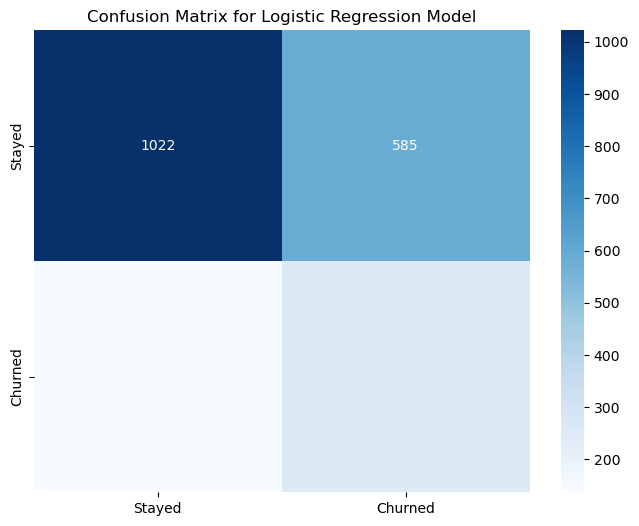

In [17]:
# lets now use a confusion matrix to visualize the performance of the model
cm_lr = confusion_matrix(y_test, lr_predictions)
# plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', xticklabels=['Stayed', 'Churned'], yticklabels=['Stayed', 'Churned'])
plt.title('Confusion Matrix for Logistic Regression Model')

# faeture importance for logistic regression model
feature_importance = pd.DataFrame({'Feature': X.columns, 'Importance': lr_model.coef_[0]})
print("Feature importance for logistic regression model:")
print(feature_importance.sort_values(by='Importance', ascending=False))

In [18]:
# lets check the correlation between the features and the target variable 'Exited' to see which features are most correlated with customer churn.
correlation_matrix = churn_data_dummy_encoded.corr()
correlation_with_target = correlation_matrix['Exited'].abs().sort_values(ascending=False)
print("Features most correlated with customer churn:")
print(correlation_with_target)

Features most correlated with customer churn:
Exited               1.000000
Age                  0.285323
Geography_Germany    0.173488
IsActiveMember       0.156128
Balance              0.118533
Gender_Female        0.106512
Gender_Male          0.106512
Geography_France     0.104955
Geography_Spain      0.052667
NumOfProducts        0.047820
CreditScore          0.027094
Tenure               0.014001
EstimatedSalary      0.012097
HasCrCard            0.007138
Name: Exited, dtype: float64


Accuracy: 0.86
Feature 'CreditScore': 0.1425
Feature 'Age': 0.2416
Feature 'Tenure': 0.0837
Feature 'Balance': 0.1397
Feature 'NumOfProducts': 0.1307
Feature 'HasCrCard': 0.0183
Feature 'IsActiveMember': 0.0385
Feature 'EstimatedSalary': 0.1456
Feature 'Geography_France': 0.0097
Feature 'Geography_Germany': 0.0213
Feature 'Geography_Spain': 0.0087
Feature 'Gender_Female': 0.0091
Feature 'Gender_Male': 0.0104


Text(0.5, 1.0, 'Confusion Matrix for Random Forest Model')

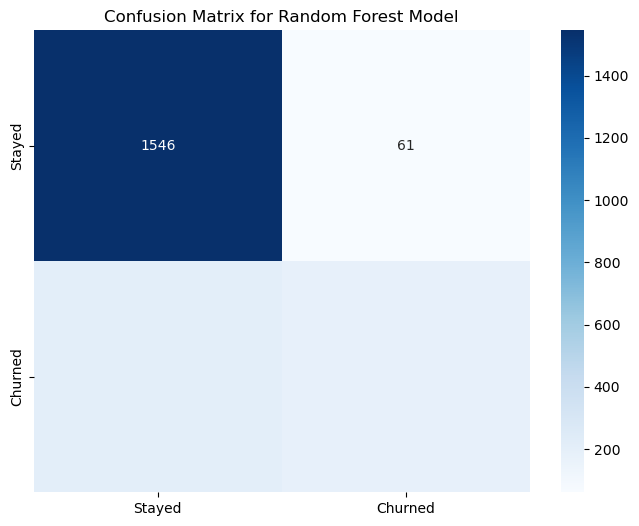

In [19]:
# lets do random forest classifier to predict customer churn using the trained and test dataset.

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)# n_estimators controls how many trees to build
rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)
rf_probabilities = rf_model.predict_proba(X_test)

print(f"Accuracy: {accuracy_score(y_test, rf_predictions):.2f}")

rf_importances = rf_model.feature_importances_
for name, importance in zip(X.columns, rf_importances):
    print(f"Feature '{name}': {importance:.4f}")

# lets now use a confusion matrix to visualize the performance of the model
cm_rf = confusion_matrix(y_test, rf_predictions)
# plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', xticklabels=['Stayed', 'Churned'], yticklabels=['Stayed', 'Churned'])
plt.title('Confusion Matrix for Random Forest Model')

In [20]:
print("\nClassification Report for Random Forest Model:\n", classification_report(y_test, rf_predictions))


Classification Report for Random Forest Model:
               precision    recall  f1-score   support

           0       0.88      0.96      0.92      1607
           1       0.75      0.47      0.58       393

    accuracy                           0.86      2000
   macro avg       0.82      0.72      0.75      2000
weighted avg       0.86      0.86      0.85      2000



XGBoost Accuracy: 0.87

Classification Report for XGBoost Model:
               precision    recall  f1-score   support

           0       0.88      0.96      0.92      1607
           1       0.75      0.48      0.58       393

    accuracy                           0.87      2000
   macro avg       0.82      0.72      0.75      2000
weighted avg       0.86      0.87      0.85      2000


Feature Importance:
              Feature  Importance
1                 Age    0.227687
4       NumOfProducts    0.216703
6      IsActiveMember    0.194544
9   Geography_Germany    0.131631
11      Gender_Female    0.064342
3             Balance    0.060095
8    Geography_France    0.028163
2              Tenure    0.018700
0         CreditScore    0.018407
7     EstimatedSalary    0.017857
5           HasCrCard    0.015423
10    Geography_Spain    0.006448
12        Gender_Male    0.000000


Text(0.5, 1.0, 'Confusion Matrix for XGBoost Model')

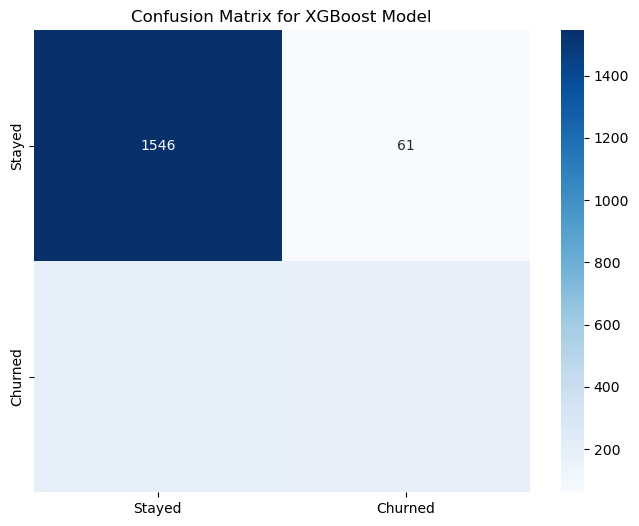

In [21]:
from xgboost import XGBClassifier


xgb_model = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42, eval_metric='logloss') # 'eval_metric' handles warnings regarding metric defaults in newer versions
xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_test)
xgb_probabilities = xgb_model.predict_proba(X_test)

print(f"XGBoost Accuracy: {accuracy_score(y_test, xgb_predictions):.2f}")
print("\nClassification Report for XGBoost Model:\n", classification_report(y_test, xgb_predictions))

importances = xgb_model.feature_importances_
feature_importance = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
print("\nFeature Importance:")
print(feature_importance.sort_values(by='Importance', ascending=False))

# lets now use a confusion matrix to visualize the performance of the model
cm_xgb = confusion_matrix(y_test, xgb_predictions)
# plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues', xticklabels=['Stayed', 'Churned'], yticklabels=['Stayed', 'Churned'])
plt.title('Confusion Matrix for XGBoost Model')

In [22]:
#Model,Accuracy,Class 1 Recall,Class 1 Precision,Class 1 F1-Score,Key Insight
#Logistic Regression (Baseline),80%,7%,45%,0.12,Lazy predictions; suffers from accuracy paradox
#Logistic Regression (Balanced),64%,65%,30%,0.41,"High recall, but creates many false positives"
#Random Forest,86%,~45%,~70%,~0.53,Captures non-linear thresholds well
#XGBoost (Gradient Boosting),87%,48%,75%,0.58,"Highest overall precision, balance, and feature leverage"

In [23]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

features = ["CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary"]
X_cluster = churn_data[features]

#cale features so distance calculations are accurate
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

#Fit the k-Means with k=4 clusters
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
churn_data["Cluster"] = kmeans.fit_predict(X_scaled)

In [24]:
churn_data.groupby("Cluster")["Exited"].mean()

Cluster
0    0.204478
1    0.120337
2    0.190919
3    0.440031
Name: Exited, dtype: float64

In [30]:
print("From the data, these are most loyal customers:")
print(churn_data[churn_data["Cluster"] == 0])

From the data, these are most loyal customers:
      CreditScore Geography  Gender  Age  Tenure    Balance  NumOfProducts  \
2             502    France  Female   42       8  159660.80              3   
5             645     Spain    Male   44       8  113755.78              2   
10            528    France    Male   31       6  102016.72              2   
31            533    France    Male   36       7   85311.70              1   
32            553   Germany    Male   41       9  110112.54              2   
...           ...       ...     ...  ...     ...        ...            ...   
9984          602   Germany    Male   35       7   90602.42              2   
9985          659    France    Male   36       6  123841.49              2   
9987          606     Spain    Male   30       8  180307.73              2   
9993          644    France    Male   28       7  155060.41              1   
9996          516    France    Male   35      10   57369.61              1   

      HasCrCard 

In [31]:
print("From the data, these are moderate risk customers:")
print(churn_data[churn_data["Cluster"] == 1])
print(churn_data[churn_data["Cluster"] == 2])

From the data, these are moderate risk customers:
      CreditScore Geography  Gender  Age  Tenure  Balance  NumOfProducts  \
0             619    France  Female   42       2      0.0              1   
3             699    France  Female   39       1      0.0              2   
6             822    France    Male   50       7      0.0              2   
11            497     Spain    Male   24       3      0.0              2   
12            476    France  Female   34      10      0.0              2   
...           ...       ...     ...  ...     ...      ...            ...   
9990          714   Germany    Male   33       3  35016.6              1   
9992          726     Spain    Male   36       2      0.0              1   
9994          800    France  Female   29       2      0.0              2   
9995          771    France    Male   39       5      0.0              2   
9997          709    France  Female   36       7      0.0              1   

      HasCrCard  IsActiveMember  Esti

In [32]:
print("these are high risk customers:")
print(churn_data[churn_data["Cluster"] == 3])

these are high risk customers:
      CreditScore Geography  Gender  Age  Tenure    Balance  NumOfProducts  \
16            653   Germany    Male   58       1  132602.88              1   
42            556    France  Female   61       2  117419.35              1   
44            660     Spain  Female   61       5  155931.11              1   
58            511     Spain  Female   66       4       0.00              1   
59            614    France    Male   51       4   40685.92              1   
...           ...       ...     ...  ...     ...        ...            ...   
9939          693     Spain  Female   57       9       0.00              2   
9948          724   Germany  Female   53       1  139687.66              2   
9967          623    France    Male   48       5  118469.38              1   
9979          677    France  Female   58       1   90022.85              1   
9991          597    France  Female   53       4   88381.21              1   

      HasCrCard  IsActiveMember 